# Data exploration

Four folders of photos, each typical photobook theme.

There are three sources of information for each photo:

1. The pixels themselves.
2. Scene labels from Amazon Rekognition, stored in a file next to each photo.
3. EXIF metadata inside the photo - when it was taken, where, and on what camera.

Purpose of this notebook is to discover what each of these sources actually tells us, how reliable it is, and what that means for writing captions.

In [55]:
import contextlib
import io
import json
import random
import re
from collections import Counter
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pycountry
import reverse_geocoder as rg
from PIL import Image, ImageOps

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 160)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA = ROOT / "data"
FOLDERS = sorted(p.name for p in DATA.iterdir() if p.is_dir())
FOLDERS

['day-at-beach',
 'garden-birthday-party',
 'skiing-holiday',
 'summer-with-grandkids']

## 1. What files are there

Each photo should have a label file next to it with an identical name plus `.json`.
First, check that every photo has its specific label file and there is nothing extra in the folders.

In [56]:
for folder in FOLDERS:
    imgs = {p.name for p in (DATA / folder).glob("*.jpg")}
    jsons = {p.name.removesuffix(".json") for p in (DATA / folder).glob("*.jpg.json")}
    others = [
        p.name for p in (DATA / folder).iterdir() if not p.name.endswith((".jpg", ".jpg.json"))
    ]
    print(
        f"{folder:25s} {len(imgs):4d} photos  {len(jsons):4d} label files  "
        f"unmatched: {sorted(imgs ^ jsons)}  other files: {others}"
    )

day-at-beach                60 photos    60 label files  unmatched: []  other files: []
garden-birthday-party       67 photos    67 label files  unmatched: []  other files: []
skiing-holiday              68 photos    68 label files  unmatched: []  other files: []
summer-with-grandkids      118 photos   118 label files  unmatched: []  other files: []


## 2. Label files

The label files are the raw output of the AWS command line tool. They look like
JSON, but the keys are not in quotes, hence a normal JSON parser consistently rejects them.

In [57]:
raw = (DATA / "day-at-beach" / "Image_1.jpg.json").read_text()
print(raw[:400])

{
  LabelModelVersion: "2.0",
  Labels: [
    {
      Confidence: 99.61465454101562,
      Instances: [{
          BoundingBox: {
            Height: 0.524233877658844,
            Left: 0.19484186172485352,
            Top: 0.27056753635406494,
            Width: 0.6263463497161865
          },
          Confidence: 98.3991470336914
        }],
      Name: "Person",
      Parents: []
    },
    {


In [58]:
try:
    json.loads(raw)
except json.JSONDecodeError as e:
    print(f"json.loads fails: {e}")

json.loads fails: Expecting property name enclosed in double quotes: line 2 column 3 (char 4)


Putting quotes around the keys is sufficient to transform them into valid JSON.

In [59]:
KEY_RE = re.compile(r"([{,\[]\s*)([A-Za-z_][A-Za-z0-9_]*)\s*:")


def parse_labels(path: Path) -> list[dict]:
    text = KEY_RE.sub(r'\1"\2":', path.read_text())
    return json.loads(text)["Labels"]


parse_labels(DATA / "day-at-beach" / "Image_1.jpg.json")[:2]

[{'Confidence': 99.61465454101562,
  'Instances': [{'BoundingBox': {'Height': 0.524233877658844,
     'Left': 0.19484186172485352,
     'Top': 0.27056753635406494,
     'Width': 0.6263463497161865},
    'Confidence': 98.3991470336914}],
  'Name': 'Person',
  'Parents': []},
 {'Confidence': 99.61465454101562,
  'Instances': [],
  'Name': 'Human',
  'Parents': []}]

In [60]:
label_files = sorted(DATA.glob("*/*.jpg.json"))
failures = []
for f in label_files:
    try:
        parse_labels(f)
    except Exception as e:
        failures.append((f.relative_to(DATA), repr(e)))

print(f"{len(label_files) - len(failures)} of {len(label_files)} label files parsed")
failures

313 of 313 label files parsed


[]

All 313 label files parse with this fix. Regex only touches a word followed
by a colon straight after `{`, `,` or `[`, which is where keys appear.
Label names such as "Party Hat" are always inside quotes, so they are never touched.

## 3. EXIF metadata

EXIF gives the time the photo was taken, GPS position, camera and orientation flag. Phones often save photos sideways and set this flag instead of rotating the pixels. Also count how many EXIF tags each photo has - real phone photos carry dozens, while edited or stock photos usually carry very few.

In [61]:
EXIF_IFD, GPS_IFD = 0x8769, 0x8825
DATETIME_ORIGINAL, DATETIME = 36867, 306
MAKE, MODEL, ORIENTATION, SOFTWARE = 271, 272, 274, 305


def to_degrees(dms, ref) -> float:
    deg = float(dms[0]) + float(dms[1]) / 60 + float(dms[2]) / 3600
    return -deg if ref in ("S", "W") else deg


def read_exif(path: Path) -> dict:
    with Image.open(path) as im:
        exif = im.getexif()
        width, height = im.size
    exif_ifd = exif.get_ifd(EXIF_IFD)
    gps = exif.get_ifd(GPS_IFD)
    raw_date = exif_ifd.get(DATETIME_ORIGINAL) or exif.get(DATETIME)
    has_gps = 2 in gps and 4 in gps
    return {
        "taken_at": datetime.strptime(raw_date, "%Y:%m:%d %H:%M:%S") if raw_date else None,
        "lat": to_degrees(gps[2], gps.get(1, "N")) if has_gps else None,
        "lon": to_degrees(gps[4], gps.get(3, "E")) if has_gps else None,
        "camera": " ".join(filter(None, [exif.get(MAKE), exif.get(MODEL)])) or None,
        "software": exif.get(SOFTWARE),
        "orientation": exif.get(ORIENTATION, 1),
        "n_exif_tags": len(exif) + len(exif_ifd) + len(gps),
        "width": width,
        "height": height,
    }


read_exif(DATA / "day-at-beach" / "Image_1.jpg")

{'taken_at': datetime.datetime(2018, 3, 8, 14, 54, 32),
 'lat': -33.891197222222225,
 'lon': 151.27769444444445,
 'camera': None,
 'software': 'Photos 4.0',
 'orientation': 1,
 'n_exif_tags': 16,
 'width': 1000,
 'height': 664}

Load into two tables:

- `photos`: one row per photo with EXIF details.
- `labels`: one row per label per photo.

In [62]:
photo_rows, label_rows = [], []

for folder in FOLDERS:
    for img in sorted((DATA / folder).glob("*.jpg")):
        found = parse_labels(img.with_name(img.name + ".json"))
        photo_rows.append(
            {"folder": folder, "file": img.name, "n_labels": len(found), **read_exif(img)}
        )
        for lab in found:
            label_rows.append(
                {
                    "folder": folder,
                    "file": img.name,
                    "label": lab["Name"],
                    "confidence": lab["Confidence"] / 100,
                    "parents": [p["Name"] for p in lab.get("Parents", [])],
                    "n_instances": len(lab.get("Instances", [])),
                }
            )

photos = pd.DataFrame(photo_rows)
photos["taken_at"] = pd.to_datetime(photos["taken_at"])
labels = pd.DataFrame(label_rows)

print(f"{len(photos)} photos, {len(labels)} label rows, {labels.label.nunique()} distinct labels")
photos.head()

313 photos, 5040 label rows, 336 distinct labels


,folder,file,n_labels,taken_at,lat,lon,camera,software,orientation,n_exif_tags,width,height
0,day-at-beach,Image_1.jpg,15,2018-03-08 14:54:32,-33.891197,151.277694,NaN,Photos 4.0,1,16,1000,664
1,day-at-beach,Image_10.jpg,12,2018-03-08 14:54:34,-33.891197,151.277694,NaN,Photos 4.0,1,16,1000,664
2,day-at-beach,Image_11.jpg,17,2018-03-08 14:54:34,-33.891197,151.277694,NaN,Photos 4.0,1,16,1000,664
3,day-at-beach,Image_12.jpg,8,2018-03-08 14:54:34,-33.891197,151.277694,NaN,Photos 4.0,1,16,1000,664
4,day-at-beach,Image_13.jpg,26,2018-03-08 14:54:34,-33.891197,151.277694,NaN,Photos 4.0,1,16,1000,664


In [63]:
photos.groupby("folder").agg(
    photos=("file", "size"),
    first_taken=("taken_at", "min"),
    last_taken=("taken_at", "max"),
    missing_date=("taken_at", lambda s: s.isna().sum()),
    missing_gps=("lat", lambda s: s.isna().sum()),
    cameras=("camera", lambda s: ", ".join(s.dropna().unique()) or "none"),
    median_exif_tags=("n_exif_tags", "median"),
    median_labels=("n_labels", "median"),
)

,photos,first_taken,last_taken,missing_date,missing_gps,cameras,median_exif_tags,median_labels
folder,,,,,,,,
day-at-beach,60,2018-03-08 14:54:32,2018-03-08 14:54:42,0,0,none,16.0,11.5
garden-birthday-party,67,2018-08-20 17:58:02,2019-02-07 16:08:23,0,0,none,16.0,10.0
skiing-holiday,68,2019-01-22 19:13:35,2020-02-07 16:10:42,0,0,none,16.0,21.0
summer-with-grandkids,118,2018-09-13 11:26:44,2018-09-14 11:43:45,0,0,Apple iPhone X,60.0,16.0


Every photo has a date and GPS position, hence no issue with missing metadata in this dataset.

Only the grandkids folder has a camera recorded and a complete set of EXIF tags. Other three folders have very few tags, which suggests they are
stock photos with a date and location added afterwards.

## 4. When were the photos taken?

In [64]:
photos["date"] = photos["taken_at"].dt.date
photos.groupby(["folder", "date"]).size().rename("photos").to_frame()


def time_summary(g: pd.DataFrame) -> pd.Series:
    t = g["taken_at"].sort_values()
    gaps = t.diff().dt.total_seconds().dropna()
    main_day = t.dt.date.mode()[0]
    on_main = t[t.dt.date == main_day]
    return pd.Series(
        {
            "main_day": main_day,
            "share_on_main_day": round(len(on_main) / len(t), 2),
            "main_day_span_minutes": round((on_main.max() - on_main.min()).total_seconds() / 60, 1),
            "median_gap_seconds": gaps.median(),
            "share_of_gaps_under_2s": round((gaps < 2).mean(), 2),
        }
    )


pd.DataFrame({folder: time_summary(g) for folder, g in photos.groupby("folder")}).T

,main_day,share_on_main_day,main_day_span_minutes,median_gap_seconds,share_of_gaps_under_2s
day-at-beach,2018-03-08,1.0,0.2,0.0,1.0
garden-birthday-party,2019-02-07,0.96,0.2,0.0,0.98
skiing-holiday,2020-02-07,0.91,0.2,0.0,0.91
summer-with-grandkids,2018-09-13,0.57,366.9,1.0,0.54


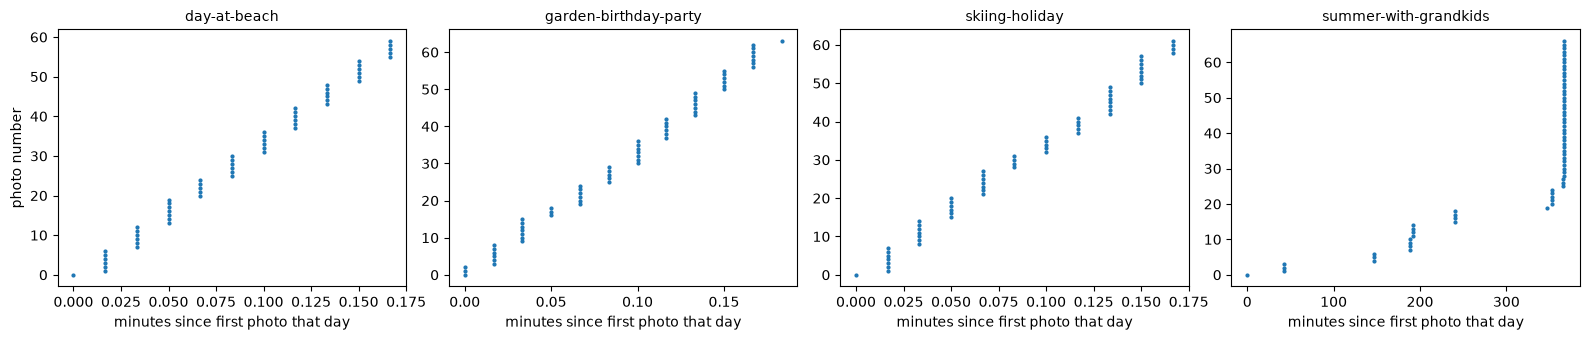

In [65]:
fig, axes = plt.subplots(1, len(FOLDERS), figsize=(16, 3.5))
for ax, (folder, g) in zip(axes, photos.groupby("folder")):
    t = g["taken_at"].sort_values()
    on_main = t[t.dt.date == t.dt.date.mode()[0]]
    minutes = (on_main - on_main.min()).dt.total_seconds() / 60
    ax.plot(minutes.values, range(len(minutes)), ".", markersize=4)
    ax.set_title(folder, fontsize=10)
    ax.set_xlabel("minutes since first photo that day")
axes[0].set_ylabel("photo number")
plt.tight_layout()
plt.show()

### Dates: findings

The three stock folders show the same pattern. On their main day, every photo is stamped within about ten seconds (`main_day_span_minutes` is 0.2), and nearly all gaps between photos are zero. Not plausible for a real day out, so timestamps were written in bulk rather than recorded at capture. Garden party and skiing also have a few outliers months earlier (3 photos in August 2018, 6 in January 2019).

Grandkids folder looks like genuine use. Photos spread over two days, about six hours of shooting on the first day, and more than half of gaps under two seconds - bursts of the same moment.

For real user photos, capture date is the most reliable fact available, so it should come from EXIF rather than a model. Pages can span more than one day, so dates need showing as ranges where needed ("13th–14th September 2018").

## 5. Location

GPS coordinates are reverse geocoded with `reverse_geocoder`, which bundles the GeoNames towns dataset and runs entirely offline. No location data leaves the
machine, which is relevant to privacy constraints.

In [66]:
coords = photos.groupby("folder").agg(
    distinct_points_1km=("lat", lambda s: s.round(2).nunique()),
    lat=("lat", "median"),
    lon=("lon", "median"),
)
coords

,distinct_points_1km,lat,lon
folder,,,
day-at-beach,1,-33.891197,151.277694
garden-birthday-party,1,51.457561,-0.035636
skiing-holiday,1,39.033683,140.546147
summer-with-grandkids,1,53.306029,-2.357750


In [67]:
with contextlib.redirect_stdout(io.StringIO()):
    geocoder = rg.RGeocoder(mode=1, verbose=False)


def place(lat: float, lon: float) -> tuple[str, str, str]:
    hit = geocoder.query([(lat, lon)])[0]
    country = pycountry.countries.get(alpha_2=hit["cc"])
    return hit["name"], hit["admin1"], country.name if country else hit["cc"]


places = pd.DataFrame(
    [place(r.lat, r.lon) for r in coords.itertuples()],
    index=coords.index,
    columns=["town", "region", "country"],
)
coords.join(places)

,distinct_points_1km,lat,lon,town,region,country
folder,,,,,,
day-at-beach,1,-33.891197,151.277694,Bondi Beach,New South Wales,Australia
garden-birthday-party,1,51.457561,-0.035636,Catford,England,United Kingdom
skiing-holiday,1,39.033683,140.546147,Yuzawa,Akita,Japan
summer-with-grandkids,1,53.306029,-2.357750,Knutsford,England,United Kingdom


In [68]:
NORTH_SEASON = {
    12: "winter",
    1: "winter",
    2: "winter",
    3: "spring",
    4: "spring",
    5: "spring",
    6: "summer",
    7: "summer",
    8: "summer",
    9: "autumn",
    10: "autumn",
    11: "autumn",
}
FLIP = {"winter": "summer", "summer": "winter", "spring": "autumn", "autumn": "spring"}


def season(ts: pd.Timestamp, lat: float) -> str:
    s = NORTH_SEASON[ts.month]
    return FLIP[s] if lat < 0 else s


photos["season"] = [season(t, lat) for t, lat in zip(photos.taken_at, photos.lat)]
photos.groupby(["folder", "season"]).size().unstack(fill_value=0)

season,autumn,summer,winter
folder,,,
day-at-beach,60,0,0
garden-birthday-party,0,3,64
skiing-holiday,0,0,68
summer-with-grandkids,118,0,0


### Location: findings

In each folder, every photo shares a single GPS position to within about a kilometre. People move during a day out, so this again points to metadata added after capture.

- Beach: Bondi Beach, Sydney, in March (autumn there).
- Garden party: Catford, SE London, mostly February.
- Skiing: Yuzawa, Akita, Japan, mostly February.
- Grandkids: Knutsford, Cheshire, September.

Two folders don't match what's in the photos. Garden party shows full summer foliage and summer clothes, yet is dated February in London. Beach photos are placed in Sydney, but several show a flat-topped mountain that looks like Table Mountain in Cape Town.

For real users, GPS is generally accurate, and place is one of the most valued parts of a caption ("Beach day in Brighton"). A cheap consistency check between metadata and scene is still worth having.

GeoNames sometimes gives a more local place than people would use ("Catford" rather than "London"), so choice of granularity is a design decision. Simple rule: town at home, town plus country abroad ("Yuzawa, Japan").

## 6. Visual inspection

`ImageOps.exif_transpose` applies EXIF orientation flag so that photos are displayed upright.

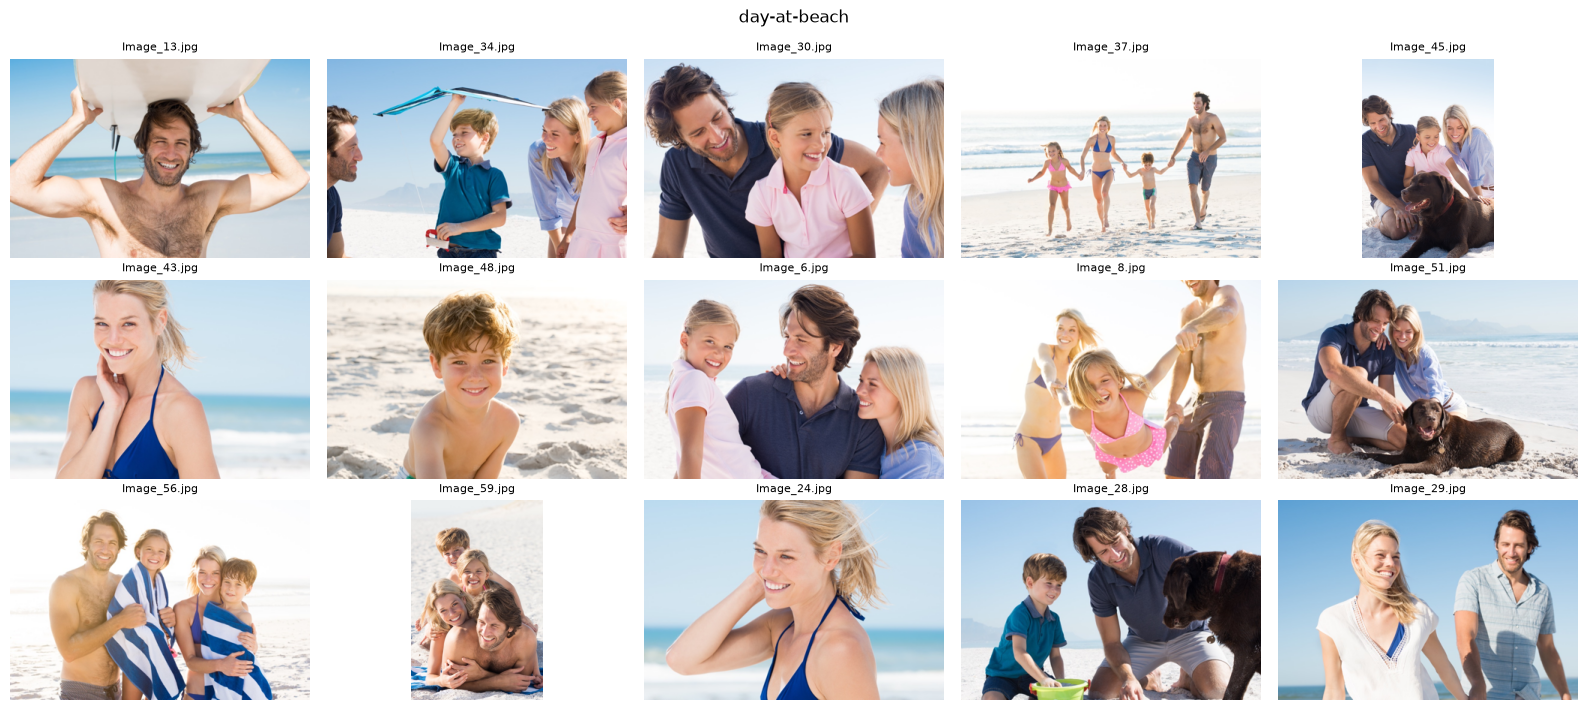

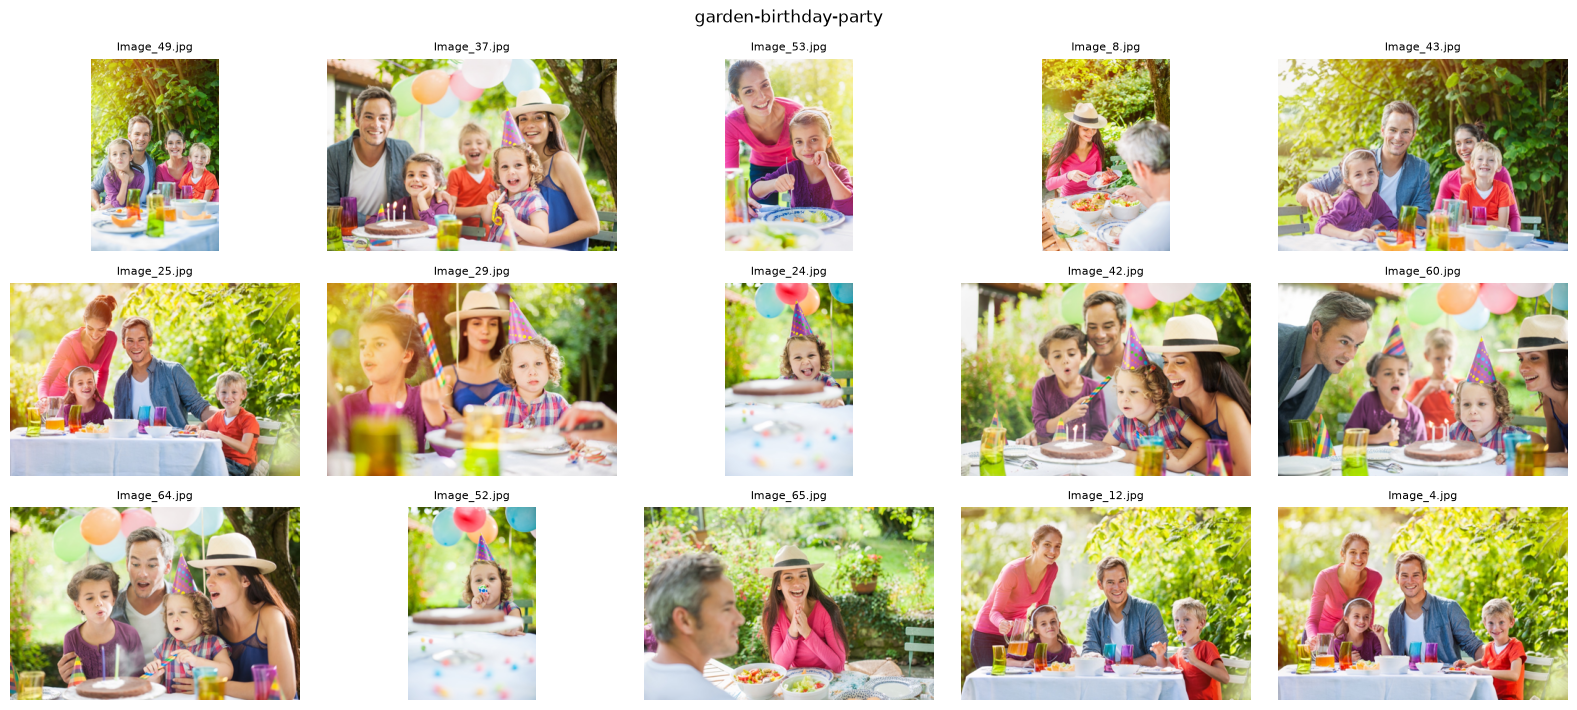

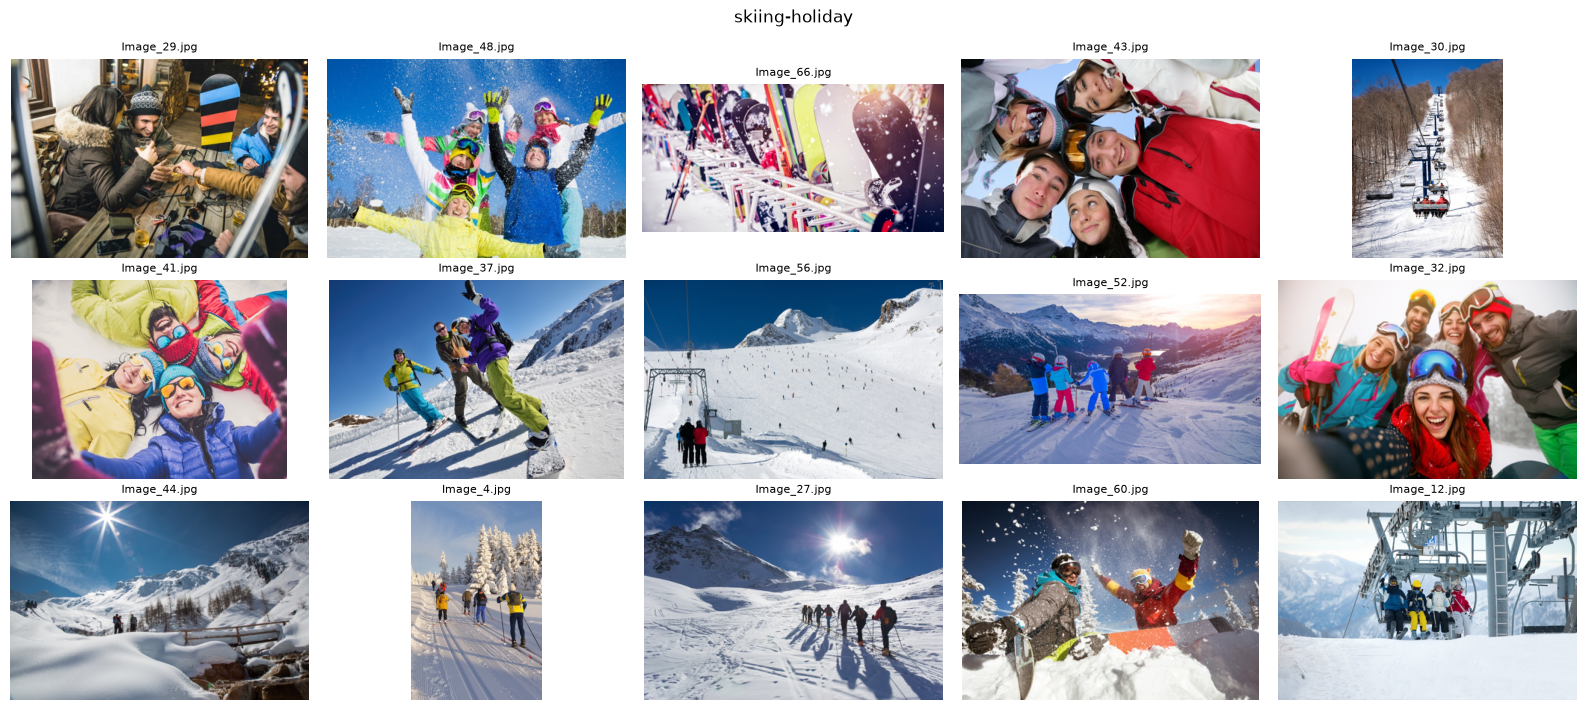

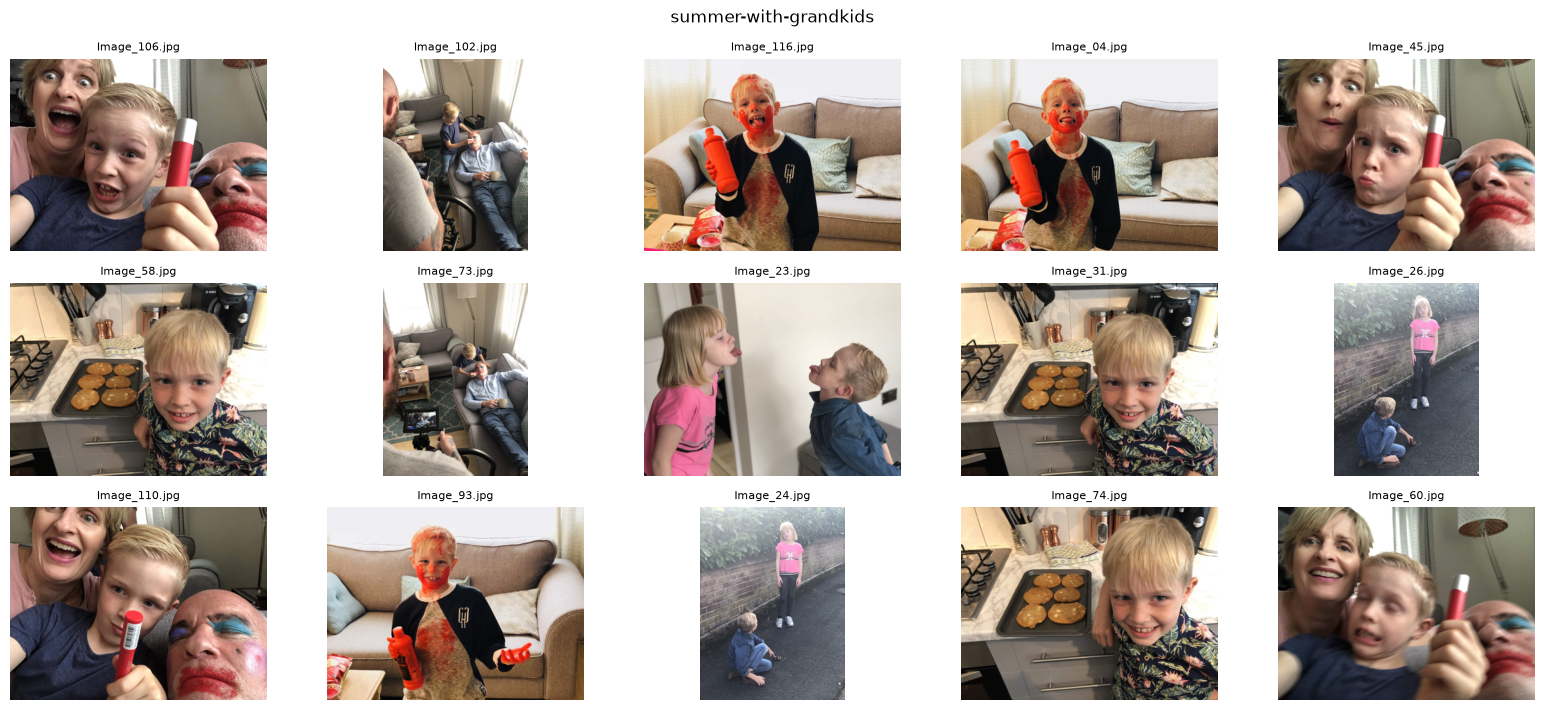

orientation,1,3,6
folder,,,
day-at-beach,60,0,0
garden-birthday-party,67,0,0
skiing-holiday,68,0,0
summer-with-grandkids,68,41,9


In [69]:
def image_number(p: Path) -> int:
    return int(p.stem.split("_")[1])


def show_grid(folder: str, n: int = 15, cols: int = 5, seed: int = 0) -> None:
    files = sorted((DATA / folder).glob("*.jpg"), key=image_number)
    random.Random(seed).shuffle(files)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 2.4 * rows))
    for ax in axes.flat:
        ax.axis("off")
    for ax, f in zip(axes.flat, files[:n]):
        with Image.open(f) as im:
            im = ImageOps.exif_transpose(im)
            im.thumbnail((400, 400))
        ax.imshow(im)
        ax.set_title(f.name, fontsize=8)
    fig.suptitle(folder, fontsize=12)
    plt.tight_layout()
    plt.show()


for folder in FOLDERS:
    show_grid(folder)

photos.groupby("folder")["orientation"].value_counts().unstack(fill_value=0)

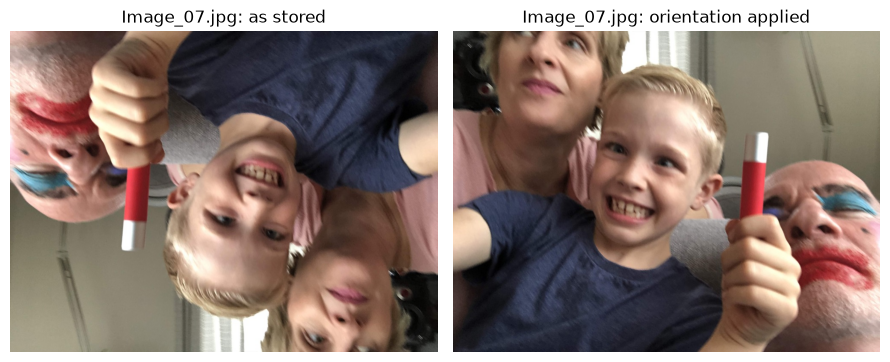

In [70]:
rotated = photos[photos.orientation != 1]
if len(rotated):
    r = rotated.iloc[0]
    with Image.open(DATA / r.folder / r.file) as im:
        as_stored = im.copy()
        corrected = ImageOps.exif_transpose(im)
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    for ax, img, title in zip(axes, [as_stored, corrected], ["as stored", "orientation applied"]):
        ax.imshow(img)
        ax.set_title(f"{r.file}: {title}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No photos with an orientation flag")

### Visual inspection: findings

Beach, garden party and skiing are professional stock photos - posed models, studio lighting, same few people throughout. Grandkids folder is genuine smartphone photos, with variable lighting, informal framing and frequent near-identical frames.

50 of the 118 grandkids photos (42%) are stored rotated, with orientation recorded only in EXIF: 41 upside down and 9 sideways. Any pixel-based model must apply this flag first, or it will be judging rotated images. Not certain whether the Rekognition labels were generated before or after correction.

Customer libraries will look far more like the grandkids folder than the stock folders, so performance on that folder should carry the most weight.

## 7. Scene labels

Distribution of label counts per photo and label confidence.

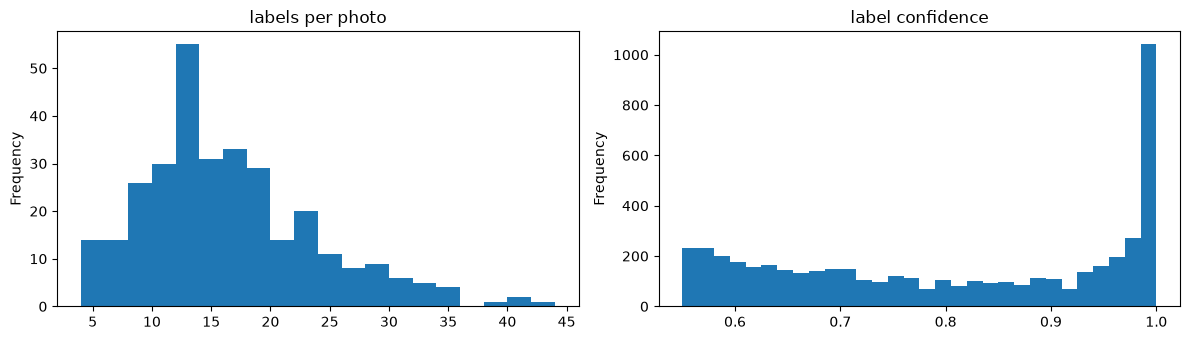

Labels per photo: median 15, range 4-44
Lowest confidence in the files: 0.55


In [71]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
photos["n_labels"].plot.hist(bins=20, ax=axes[0], title="labels per photo")
labels["confidence"].plot.hist(bins=30, ax=axes[1], title="label confidence")
plt.tight_layout()
plt.show()

print(
    f"Labels per photo: median {photos.n_labels.median():.0f}, "
    f"range {photos.n_labels.min()}-{photos.n_labels.max()}"
)
print(f"Lowest confidence in the files: {labels.confidence.min():.2f}")

Lowest confidence is 0.55, so labels were requested with a confidence cut-off and less certain ones were discarded upstream. A threshold of 0.5 therefore keeps every label. Filtering has to come from which labels are used, not their confidence.

"Share" below means the proportion of photos in a folder carrying a label.

In [72]:
MIN_CONF = 0.5
strong = labels[labels.confidence >= MIN_CONF].drop_duplicates(["folder", "file", "label"])
n_photos = photos.groupby("folder").size()

share = strong.groupby(["folder", "label"]).size().div(n_photos, level="folder").rename("share")
overall = strong.label.value_counts().div(len(photos)).rename("share_all_photos")

overall.head(15).round(2)

label
Person         0.99
Human          0.99
People         0.62
Apparel        0.59
Clothing       0.59
Female         0.38
Face           0.38
Girl           0.34
Photography    0.32
Photo          0.32
Portrait       0.26
Outdoors       0.26
Food           0.24
Nature         0.23
Family         0.21
Name: share_all_photos, dtype: float64

In [73]:
def as_columns(d: dict[str, list[str]]) -> pd.DataFrame:
    """Lists of different lengths side by side."""
    return pd.DataFrame({k: pd.Series(v) for k, v in d.items()})


top_by_folder = {
    folder: [
        f"{lab} ({s:.0%})" for lab, s in share[folder].sort_values(ascending=False).head(15).items()
    ]
    for folder in FOLDERS
}
as_columns(top_by_folder)

,day-at-beach,garden-birthday-party,skiing-holiday,summer-with-grandkids
0,Human (100%),Person (100%),Person (97%),Human (99%)
1,Person (100%),Human (100%),Human (97%),Person (99%)
2,People (90%),People (97%),Outdoors (79%),Indoors (55%)
3,Family (65%),Apparel (72%),Clothing (78%),Clothing (50%)
4,Female (45%),Clothing (72%),Apparel (78%),Face (50%)
5,Face (42%),Hat (69%),Nature (76%),Apparel (50%)
6,Apparel (40%),Party Hat (55%),Snow (65%),Kid (44%)
7,Photography (40%),Female (42%),Sports (54%),Child (44%)
8,Photo (40%),Food (42%),Sport (54%),Female (42%)
9,Clothing (40%),Girl (40%),People (53%),Girl (41%)


### Discriminative labels

Informative labels are identified by lift i.e. the share of a label within a folder divided by its share across all photos.

In [74]:
lift = share.reset_index()
lift["share_all_photos"] = lift.label.map(overall)
lift["lift"] = lift.share / lift.share_all_photos

distinctive = (
    lift[lift.share >= 0.10].sort_values("lift", ascending=False).groupby("folder").head(10)
)
as_columns(
    {
        folder: [
            f"{r.label} ({r.share:.0%})"
            for r in distinctive[distinctive.folder == folder].itertuples()
        ]
        for folder in FOLDERS
    }
)

,day-at-beach,garden-birthday-party,skiing-holiday,summer-with-grandkids
0,Working Out (10%),Cake (19%),Snow (65%),Mouth (10%)
1,Exercise (10%),Party Hat (55%),Piste (46%),Appliance (20%)
2,Spring Break (10%),Birthday Party (36%),Winter (16%),Lip (10%)
3,Swimwear (18%),Picnic (16%),Abies (12%),Oven (15%)
4,Coast (15%),Eating (10%),Mountain Range (34%),Cookie (23%)
5,Shoreline (15%),Beer (27%),Skiing (34%),Thumbs Up (19%)
6,Beach (13%),Alcohol (27%),Cap (18%),Bun (22%)
7,Ocean (15%),Hat (69%),Sled (12%),Sweets (25%)
8,Sea (15%),Drink (27%),Slide (13%),Bread (28%)
9,Tourist (20%),Beverage (27%),Mountain (46%),Biscuit (23%)


High lift doesn't mean useful. The most distinctive beach labels are Working Out, Exercise and Spring Break, ahead of Beach and Shoreline. Skiing gets Slide and Abies (fir trees), grandkids gets Mouth and Lip. Statistics alone pick up whatever happens to be in the stock shoot, so the mapping from labels to occasions needs a human-checked list.

In [75]:
HEADLINE = {
    "day-at-beach": "Beach",
    "garden-birthday-party": "Birthday Party",
    "skiing-holiday": "Skiing",
    "summer-with-grandkids": "Child",
}
THEME = {
    "day-at-beach": {"Beach", "Shoreline", "Coast", "Sea", "Ocean", "Sand", "Swimwear"},
    "garden-birthday-party": {"Birthday Party", "Birthday Cake", "Party Hat", "Party", "Balloon"},
    "skiing-holiday": {"Skiing", "Piste", "Snowboarding", "Slope", "Ski Lift"},
    "summer-with-grandkids": {
        "Cookie",
        "Biscuit",
        "Oven",
        "Cooktop",
        "Baking",
        "Couch",
        "Living Room",
    },
}

label_sets = strong.groupby(["folder", "file"])["label"].apply(set)
photos["label_set"] = [label_sets.get((f, fl), set()) for f, fl in zip(photos.folder, photos.file)]
photos["has_headline"] = [HEADLINE[f] in s for f, s in zip(photos.folder, photos.label_set)]
photos["has_theme"] = [bool(THEME[f] & s) for f, s in zip(photos.folder, photos.label_set)]

photos.groupby("folder").agg(
    headline=("folder", lambda s: HEADLINE[s.iloc[0]]),
    share_with_headline=("has_headline", "mean"),
    share_with_any_theme_label=("has_theme", "mean"),
).round(2)

,headline,share_with_headline,share_with_any_theme_label
folder,,,
day-at-beach,Beach,0.13,0.27
garden-birthday-party,Birthday Party,0.36,0.61
skiing-holiday,Skiing,0.34,0.50
summer-with-grandkids,Child,0.44,0.63


Even with a generous set of related labels, many photos carry no evidence of the occasion. Only 27% of beach photos have any beach-related label, and only 13% (about one in eight) have "Beach" itself. Most are close portraits against sky. The other folders sit between 50% and 63%.

### Synonymous labels

Rekognition frequently returns several names for one concept with identical confidence (e.g. "Person" and "Human"). Such pairs inflate label counts and
could introduce repetition into a naive caption.

In [76]:
together, same_conf = Counter(), Counter()
for _, g in labels.groupby(["folder", "file"]):
    conf = dict(zip(g.label, g.confidence))
    names = sorted(conf)
    for i, a in enumerate(names):
        for b in names[i + 1 :]:
            together[(a, b)] += 1
            if abs(conf[a] - conf[b]) < 1e-9:
                same_conf[(a, b)] += 1

synonyms = pd.DataFrame(
    [
        {"pair": f"{a} / {b}", "photos_together": n, "same_confidence": same_conf[(a, b)] / n}
        for (a, b), n in together.items()
        if n >= 10
    ]
)
synonyms[synonyms.same_confidence >= 0.95].sort_values("photos_together", ascending=False).head(15)

,pair,photos_together,same_confidence
26,Human / Person,310,1.000000
62,Apparel / Clothing,184,1.000000
138,Photo / Photography,99,1.000000
7,Child / Kid,64,1.000000
145,Sport / Sports,45,1.000000
856,Couch / Furniture,42,0.976190
360,Accessories / Accessory,36,1.000000
1022,Cooktop / Indoors,30,0.966667
1008,Confectionery / Sweets,30,1.000000
950,Biscuit / Cookie,27,1.000000


### Implausible labels

Certain labels are inappropriate for personal photos. They reflect a model trained on general web imagery, where a person in a polo shirt may plausibly be a doctor.

In [77]:
ODD = [
    "Doctor",
    "Veterinarian",
    "Dating",
    "Spring Break",
    "Bakery",
    "Shop",
    "Costume",
    "Working Out",
    "Slide",
    "Toy",
]
odd = strong[strong.label.isin(ODD)]
odd.groupby(["label", "folder"]).agg(
    photos=("file", "nunique"),
    mean_confidence=("confidence", "mean"),
).round(2)

photos  mean_confidence
label        folder                                        
Bakery       summer-with-grandkids      16             0.63
Costume      skiing-holiday              9             0.66
             summer-with-grandkids       1             0.64
Dating       day-at-beach                7             0.86
             garden-birthday-party       7             0.80
             skiing-holiday              4             0.62
Doctor       day-at-beach                3             0.84
Shop         skiing-holiday              1             0.69
             summer-with-grandkids      16             0.63
Slide        skiing-holiday              9             0.65
Spring Break day-at-beach                6             0.62
Toy          day-at-beach                4             0.82
             skiing-holiday              9             0.65
Veterinarian day-at-beach                2             0.74
Working Out  day-at-beach                6             0.74

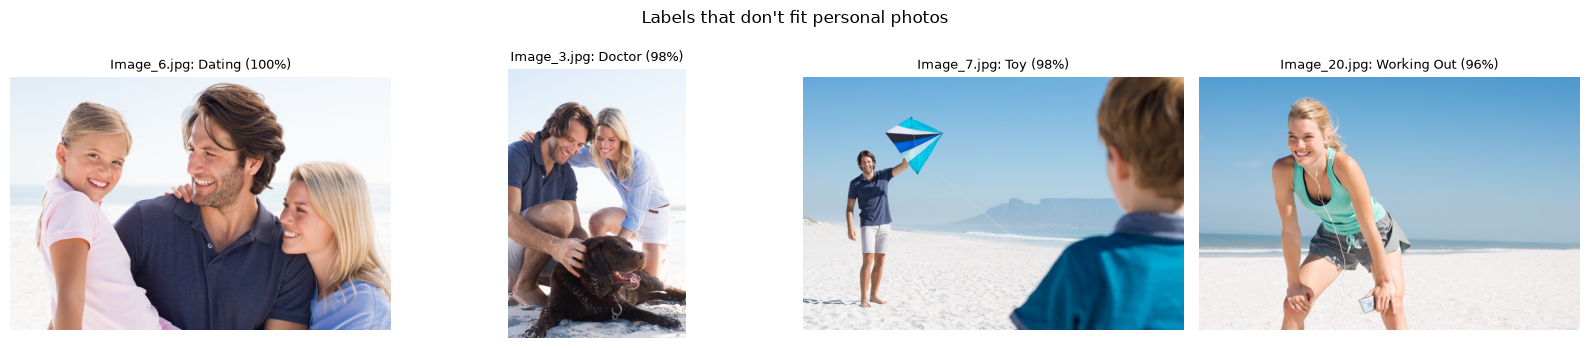

In [78]:
def show_photos(rows: pd.DataFrame, title: str) -> None:
    fig, axes = plt.subplots(1, len(rows), figsize=(4 * len(rows), 3.5))
    for ax, r in zip(np.atleast_1d(axes), rows.itertuples()):
        with Image.open(DATA / r.folder / r.file) as im:
            ax.imshow(ImageOps.exif_transpose(im))
        ax.set_title(f"{r.file}: {r.label} ({r.confidence:.0%})", fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


examples = odd.sort_values("confidence", ascending=False).drop_duplicates("label").head(4)
show_photos(examples, "Labels that don't fit personal photos")

### Scene labels: findings

- Labels are informative only after filtering. Most frequent are generic, many are synonyms or parent/child pairs (Human/Person, Biscuit/Cookie, Couch/Furniture), and some are implausible for personal photos ("Doctor", "Dating", "Bakery" for a home kitchen).
- Wrong labels can be confident. "Dating" averages 0.86 on the beach photos and "Doctor" 0.84, so a confidence threshold won't remove them.
- Small set of specific labels separates the occasions well: Party Hat and Birthday Party, Piste and Skiing, Shoreline and Sea, Cookie and Oven.
- Many single photos carry no occasion evidence at all.

Raw labels shouldn't go into captions directly. Better to map them onto a small set of occasions people actually make books about, with weights for informative labels and an ignore list for the rest. Given how often single photos are ambiguous, decision should pool evidence across all photos on a page, and where possible across other photos from the same occasion.

## 8. Evidence per page

A page holds one to three photos. For randomly sampled pages from each folder, how often does at least one photo carry an occasion-related label.

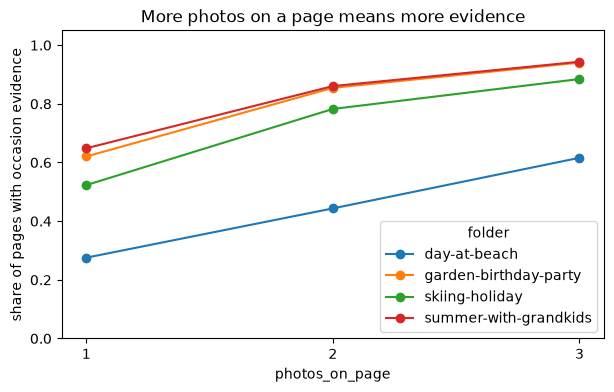

folder,day-at-beach,garden-birthday-party,skiing-holiday,summer-with-grandkids
photos_on_page,,,,
1,0.28,0.62,0.52,0.65
2,0.44,0.85,0.78,0.86
3,0.62,0.94,0.88,0.94


In [79]:
rng = random.Random(42)
rows = []
for folder in FOLDERS:
    flags = photos.loc[photos.folder == folder, "has_theme"].tolist()
    for k in (1, 2, 3):
        hits = [any(rng.sample(flags, k)) for _ in range(2000)]
        rows.append({"folder": folder, "photos_on_page": k, "pages_with_evidence": np.mean(hits)})

sim = pd.DataFrame(rows).pivot(
    index="photos_on_page", columns="folder", values="pages_with_evidence"
)
ax = sim.plot(marker="o", figsize=(7, 4), ylim=(0, 1.05))
ax.set_xticks([1, 2, 3])
ax.set_ylabel("share of pages with occasion evidence")
ax.set_title("More photos on a page means more evidence")
plt.show()
sim.round(2)

### Evidence per page: findings

Chance that a page shows the occasion rises quickly with the number of photos. Going from one photo to three takes garden party from 62% to 94% and skiing from 52% to 88%. Beach is the hard case: 28% with one photo and still only 62% with three. Most useful extra signal for these pages is other photos from the same day and place, which the curation step already groups together.

One caveat - these pages are random picks across each folder. Real pages tend to hold photos taken close together, which look alike, so the gain from extra photos will be smaller in practice. Evaluation should cover both random and consecutive pages.

## 9. Near-duplicates

Phone libraries are full of bursts, several shots of the same moment. To find them, each photo gets a 64-bit fingerprint using a difference hash (dHash).
Photo is shrunk to 9×8 greyscale pixels, and each bit records whether brightness goes up from one pixel to the next. Photos whose fingerprints differ by only a few bits are treated as near duplicates.

In [80]:
def dhash(path: Path) -> np.ndarray:
    with Image.open(path) as im:
        small = ImageOps.exif_transpose(im).convert("L").resize((9, 8), Image.Resampling.LANCZOS)
    a = np.asarray(small, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()


def near_duplicate_groups(hashes: np.ndarray, max_bits: int = 6) -> list[int]:
    dist = (hashes[:, None, :] != hashes[None, :, :]).sum(-1)
    parent = list(range(len(hashes)))

    def find(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, j in zip(*np.where(np.triu(dist <= max_bits, k=1))):
        parent[find(i)] = find(j)
    return [find(i) for i in range(len(hashes))]


photos["dhash"] = [dhash(DATA / f / fl) for f, fl in zip(photos.folder, photos.file)]
photos["dup_group"] = ""

dup_rows = []
for folder, g in photos.groupby("folder"):
    groups = near_duplicate_groups(np.stack(g["dhash"].values))
    photos.loc[g.index, "dup_group"] = [f"{folder}:{x}" for x in groups]
    sizes = Counter(groups)
    dup_rows.append(
        {
            "folder": folder,
            "photos": len(g),
            "distinct_moments": len(sizes),
            "largest_group": max(sizes.values()),
            "share_in_a_group": sum(n for n in sizes.values() if n > 1) / len(g),
        }
    )
pd.DataFrame(dup_rows).set_index("folder").round(2)

,photos,distinct_moments,largest_group,share_in_a_group
folder,,,,
day-at-beach,60,60,1,0.00
garden-birthday-party,67,66,2,0.03
skiing-holiday,68,68,1,0.00
summer-with-grandkids,118,80,14,0.42


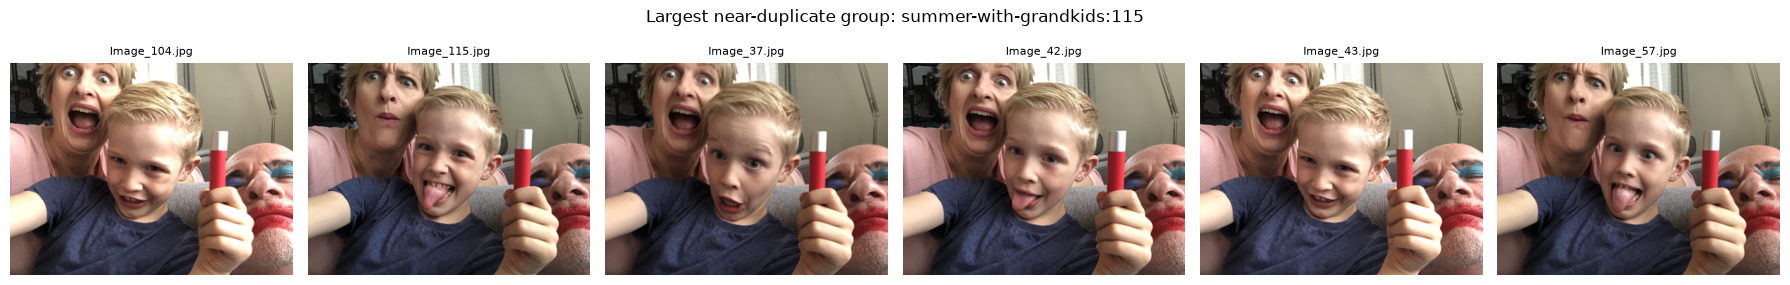

In [81]:
biggest = photos.dup_group.value_counts().index[0]
members = photos[photos.dup_group == biggest].head(6)

fig, axes = plt.subplots(1, len(members), figsize=(3 * len(members), 3))
for ax, r in zip(np.atleast_1d(axes), members.itertuples()):
    with Image.open(DATA / r.folder / r.file) as im:
        im = ImageOps.exif_transpose(im)
        im.thumbnail((400, 400))
    ax.imshow(im)
    ax.set_title(r.file, fontsize=8)
    ax.axis("off")
fig.suptitle(f"Largest near-duplicate group: {biggest}")
plt.tight_layout()
plt.show()

### Near-duplicates: findings

Stock folders have essentially no near-duplicates (one pair in garden party). Grandkids folder has lots: 118 photos collapse to 80 distinct moments, 42% of photos sit in a group, and the largest group has 14 shots of the same moment. The 6-bit threshold is a judgement call, so groups are worth checking by eye.

Significant in three places:

- **Curation.** Step before captioning should keep one photo per moment.
- **Captions.** Neighbouring pages from the same moment would get the same caption over and over. Variety needs handling across the whole book.
- **Evaluation.** Sampling pages from a folder full of duplicates makes results look better than they are, since the same evidence is counted several times. Evaluation pages should be sampled after removing duplicates.

## 10. Summary

**Date and place come from EXIF, not a model.** Every photo here has a date and GPS position. As text ("September 2018", "Knutsford") they are the most useful
and most trustworthy parts of a caption, and place names can be looked up offline. Pipeline still has to cope when EXIF is missing, which is common in real libraries.

**Metadata can be wrong, so check it against the scene.** Three of four folders have stamped dates and a single GPS position, and two contradict what's in the photos (summer garden dated February, Cape Town scenery placed in Sydney). A simple season check catches some of this.

**Labels are evidence, not caption text.** They need filtering (generic, synonyms, wrong ones) and mapping onto a small set of occasions. A few specific labels separate the occasions well.

**One photo is often not enough.** Many photos show nothing about the occasion. Using every photo on the page helps a lot, and using other photos from the same day helps single-photo pages most.

**Real photos are messier than stock.** Orientation flags, bursts and everyday scenes are normal. Grandkids folder is closest to real customer data, so its results matter most.

**Folder names give weak labels for evaluation.** No reference captions, but each folder is a known occasion. So we can check if the pipeline picks the right occasion for pages from each folder, and if dates and places in captions match EXIF.

This leads to the approach in the second notebook. Extract the facts (date, place, occasion) from metadata and labels first, then write the caption from those facts only.